In [76]:
import h5py
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
import numpy as np

# Paths
base_dir   = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
data_path  = base_dir / "Data"
num_file = data_path / "Numerical/simulation_data.h5"
ana_file = data_path / "Analytical/simulation_data.h5"

# Load
with h5py.File(num_file, "r") as f_num, h5py.File(ana_file, "r") as f_ana:
    x_num = f_num["x"][:]
    t_num = f_num["times"][:]
    E_num = f_num["energies"][:]

    x_ana = f_ana["x"][:]
    t_ana = f_ana["times"][:]
    E_ana = f_ana["energies"][:]

    psi_num = f_num["psi_prob"][:]   # shape (n_states, n_steps, N)
    psi_ana = f_ana["psi_prob"][:]

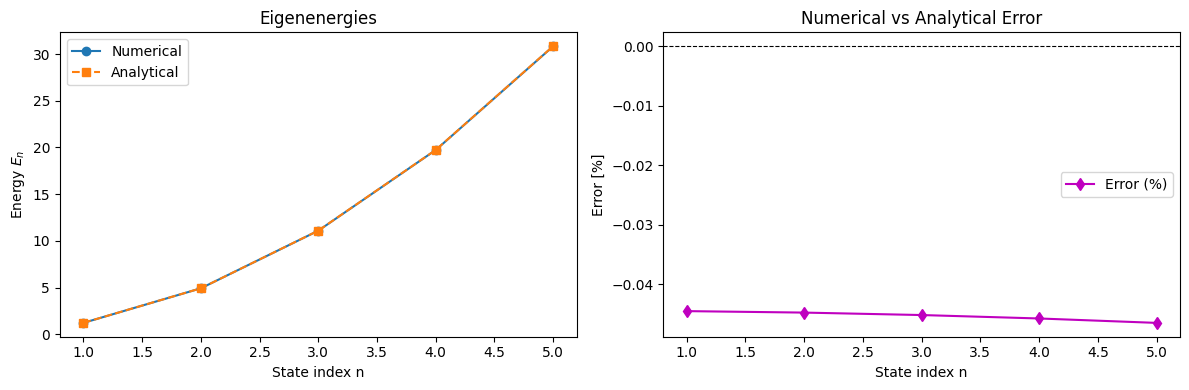

In [77]:
# --- Percentage error ---
error_percent = 100 * (E_num - E_ana) / E_ana

# --- Two plots side by side ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left plot: Energies
axes[0].plot(range(1, len(E_num)+1), E_num, 'o-', label="Numerical")
axes[0].plot(range(1, len(E_ana)+1), E_ana, 's--', label="Analytical")
axes[0].set_xlabel("State index n")
axes[0].set_ylabel("Energy $E_n$")
axes[0].set_title("Eigenenergies")
axes[0].legend()

# Right plot: Error %
axes[1].plot(range(1, len(error_percent)+1), error_percent, 'd-m', label="Error (%)")
axes[1].axhline(0, color='k', linestyle='--', linewidth=0.8)
axes[1].set_xlabel("State index n")
axes[1].set_ylabel("Error [%]")
axes[1].set_title("Numerical vs Analytical Error")
axes[1].legend()

# Layout + Save
plt.tight_layout()
plt.savefig(
    'Figs/Eigenenergies_with_Error.png',
    dpi=300,
    format='png',
    facecolor='white',
    edgecolor='black',
    transparent=True
)
plt.show()

In [78]:

def plot_snapshot(state=0, time_index=0, analytical=None, numeric=None):
    """
    Plot numerical and analytical probability densities at a given time.

    Parameters
    ----------
    state       : int
        Just for labeling (doesn't affect computation).
    time_index  : int
        Time snapshot index.
    analytical  : tuple (x, psi) or None
        Analytical wavefunction(s). psi can be:
          - 1D array (single snapshot in x)
          - 2D array (time, x)
    numeric     : tuple (x, psi) or None
        Numerical wavefunction(s), same format as analytical.
    """
    plt.figure(figsize=(7,4))

    if numeric is not None:
        x_num, psi_num = numeric
        if psi_num.ndim == 1:
            psi_num_t = np.abs(psi_num)**2
        elif psi_num.ndim == 2:
            psi_num_t = np.abs(psi_num[time_index, :])**2
        else:
            raise ValueError("psi_num must be 1D or 2D")
        plt.plot(x_num, psi_num_t, label=f"Numerical")

    if analytical is not None:
        x_ana, psi_ana = analytical
        if psi_ana.ndim == 1:
            psi_ana_t = np.abs(psi_ana)**2
        elif psi_ana.ndim == 2:
            psi_ana_t = np.abs(psi_ana[time_index, :])**2
        else:
            raise ValueError("psi_ana must be 1D or 2D")
        plt.plot(x_ana, psi_ana_t, '--', label="Analytical")

    plt.xlabel("x")
    plt.ylabel(r"$|\psi(x,t)|^2$")
    plt.title(fr"The $|\psi(x,t)|^2$ at state {state}, t = {time_index}")
    plt.legend()

    plt.savefig(
    f'Figs/ProbabilityDensity_n{state}_t{time_index}.png',
    dpi=300,
    format='png',
    facecolor='white',
    edgecolor='black',
    transparent=True
)
    plt.show()

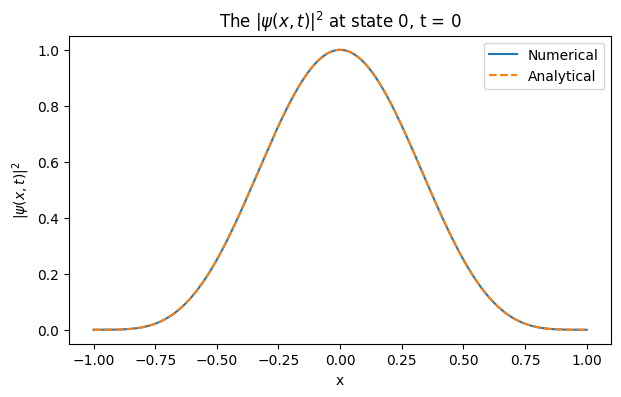

In [79]:
'''-----Parameters-----'''
n = 0       #The State
t = 0       #The Time Snapshot

with h5py.File(num_file, "r") as f_num, h5py.File(ana_file, "r") as f_ana:
    psi_num = f_num["psi_prob"][n,:,:]

plot_snapshot(
    state=n,
    time_index=t,
    analytical=(x_ana, psi_ana[n]),
    numeric=(x_num, psi_num)
)
